---
title: The Connected River (Part 1) - Building
short_title: The Connected River (Part 1) - Building
subtitle: A reusable workflow for joining environmental monitoring data through river networks
description: A reproducible notebook and supporting Python workflow for acquiring, harmonising and matching river-monitoring data.
date: "2026-09-26"
updated: "2026-09-30"
license: MIT

affiliations:
  - id: ukceh
    institution: UK Centre for Ecology & Hydrology
    url: https://www.ceh.ac.uk

authors:
  - name: Lily Gouldsbrough
    affiliations:
      - ukceh

funding:
  - statement: This work was carried out as part of the UK Environmental Exposure Hub (EEX), developed through the UKCEH National Capability for UK Challenges (NC-UK) programme and funded by NERC.
    award:
      id: NE/Y006208/1
      name: UKCEH National Capability for UK Challenges Programme
---

# The Connected River (Part 1) - Building

**A reusable workflow for joining environmental monitoring data through river networks**

*This work was carried out as part of the UK Environmental Exposure Hub (EEX Hub), developed through the UKCEH National Capability for UK Challenges (NC-UK) programme and funded by NERC (NE/Y006208/1).*

## What this notebook does

Biology, chemistry and pressure data are collected by different monitoring programmes,
often at different places and times. This notebook shows how I brought those records
together to build an England-wide dataset at biological-survey level.

The main problem is deciding which chemistry station can reasonably represent each
biological survey. The workflow traces possible connections through the river network,
compares the available evidence and records why a match was accepted or rejected. The
England-wide example demonstrates the method; the reusable matching workflow is the main
output.

**Question:** How can monitoring datasets collected at different places and times be
joined defensibly through a river network?

## Before running

Edit the settings below, then choose **Restart Kernel and Run All**. `build_england`
downloads and processes the national example. The first run can take several hours, but
downloads and completed stages are cached. `use_existing` reopens a finished output.

Two UKCEH inputs need to be obtained separately under their own licence terms:

- [UKCEH river-network access and licensing](https://www.ceh.ac.uk/data/15000-watercourse-network)
- [Hydrometric Areas with Coastline](https://catalogue.ceh.ac.uk/documents/1957166d-7523-44f4-b279-aa5314163237)

The workflow needs the topology-enabled UKCEH river-network CSV, including link and node
identifiers; a line-only map layer is not sufficient. Set both local paths in the settings
cell. The run information records which files were
used; the source files themselves are not copied into the output. Once this notebook
has finished, [The Connected River (Part 2) - Exploring](./The_Connected_River_Part_2_Exploring.ipynb)
opens the completed output for the maps and analysis.

### Settings for most runs

Start here before choosing **Restart Kernel and Run All**. For the England-wide build,
most users only need to choose the run mode, provide the two licensed spatial inputs and
set the final year. The workspace and refresh values can usually stay as they are.

- Use `build_england` to create or update the national dataset.
- Use `use_existing` with a completed output to inspect the method without rebuilding.
- Paths may be absolute or relative to this repository.

In [1]:
# SETTINGS FOR MOST RUNS
import os

RUN_MODE = os.environ.get("BCR_RUN_MODE", "build_england")
# "build_england" creates the national example from source.
# "use_existing" reopens an output already created by this notebook.

WORKSPACE_DIRECTORY = os.environ.get(
    "BCR_METHOD_WORKSPACE", "connected_river_workspace"
)
EXISTING_RELEASE_DIRECTORY = os.environ.get("BCR_RELEASE_DIR", "")

TARGET_YEAR = 2025
REFRESH_RECENT_YEARS = 2

# Request the topology-enabled UKCEH network, then point to its CSV or authorised ZIP.
NETWORK_MODE = "ukceh_irn"  # use "custom_irn_schema" for another network
NETWORK_INPUT = os.environ.get("BCR_NETWORK_INPUT", "")

# Download this separately, then point to its ZIP or extracted folder.
HYDROLOGICAL_AREAS_INPUT = os.environ.get("BCR_HYDROLOGICAL_AREAS_INPUT", "")

IRN_ACCESS_PAGE = "https://www.ceh.ac.uk/data/15000-watercourse-network"
HYDROMETRIC_AREAS_ACCESS_PAGE = "https://catalogue.ceh.ac.uk/documents/1957166d-7523-44f4-b279-aa5314163237"

### Advanced matching settings

The settings below define the matching recipe. Change them when testing another temporal
window, restricting eligible routes, changing the 100-point ranking or supplying a
different directed river network. Leave them unchanged to reproduce the default example.

In [2]:
# ADVANCED SETTINGS - edit when adapting the matching recipe

# Map another directed network to the fields expected by the workflow.
CUSTOM_NETWORK_COLUMNS = {
    "edge_id": "edge_id",
    "from_node": "from_node",
    "to_node": "to_node",
    "length_m": "length_m",
    "geometry_wkt": "geometry_wkt",
    "strahler": "strahler",        # optional
    "shreve": "shreve",            # optional
    "river_name": "river_name",    # optional
    "area_id": "area_id",          # optional
}

MATCHING_OPTIONS = {
    "antecedent_window_months": 6,  # use 12 for the previous year
    "max_euclidean_distance_m": 15_000,
    "max_network_distance_m": 10_000,
    "max_snap_distance_m": 1_000,
    "max_acceptable_snap_distance_m": 250,
    "min_wq_samples_per_year": 3,
    "min_wq_target_determinands": 3,
    "candidate_direction": "either_direction",  # or "upstream_only"
    "allow_downstream_wq": True,
}

# Applied before ranking. Multiple rules use AND logic.
# Examples:
# ["wq_has_metals:eq:true"]
# ["network_direction:eq:wq_upstream_of_bio"]
# ["path_permitted_sewage_outlets:gt:0"]
# ["path_permitted_sewage_outlets:gt:0",
#  "network_direction:eq:wq_upstream_of_bio"]
CANDIDATE_ROUTE_FILTERS = []

# Alternative component points must total exactly 100.
CUSTOM_MATCH_RECIPE = None
# CUSTOM_MATCH_RECIPE = {
#     "name": "chemistry_emphasis",
#     "year_min": 2018,
#     "base_component_points": {
#         "score_distance": 25, "score_snap": 15,
#         "score_temporal": 20, "score_chemistry": 30,
#         "score_transport_plausibility": 10,
#     },
#     "evidence_terms": [],
#     "allowed_review_reasons": [],
# }

## Build the evidence base

The next cell imports the project functions and either builds or reopens the output. Most
of it is setup, so the cell is folded. The implementation is kept in ordinary Python
modules under `connected_river/`, leaving the main steps visible in the notebook.

In [3]:
from __future__ import annotations

import importlib.util
import json
from pathlib import Path

required_modules = (
    "duckdb", "geopandas", "matplotlib", "networkx", "numpy",
    "pandas", "pyarrow", "pydeck", "pyproj", "requests", "scipy", "PIL",
    "shapely", "sklearn", "yaml",
)
missing = [name for name in required_modules if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError(
        "Missing packages: " + ", ".join(missing)
        + ". Create the environment described in README.md, then rerun."
    )

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from connected_river.analysis.custom_matching_recipe import (
    EXAMPLE_CHEMISTRY_EMPHASIS_RECIPE, apply_custom_matching_recipe,
    recipe_terms_table, select_custom_matches,
)
from connected_river.download.catalog import load_catalog
from connected_river.figures import (
    compare_matching_recipes, compare_recipe_weights, dataframe_markdown,
    plot_candidate_decision_example, plot_matching_outcomes,
    plot_network_coverage, plot_temporal_join, plot_workflow_overview,
)
from connected_river.matching.prefilter import apply_table_filters
from connected_river.outputs import inspect_completed_dataset, write_matching_outputs
from connected_river.validation.match_decisions import select_candidates_by_scientific_gate
from connected_river.workflow import build_or_resume, network_contract_table

REPOSITORY_ROOT = Path.cwd().resolve()
if not (REPOSITORY_ROOT / "connected_river").is_dir():
    raise RuntimeError(
        "Open this notebook from the repository root so the connected_river folder is available."
    )

run = build_or_resume(
    repository_root=REPOSITORY_ROOT,
    workspace_directory=WORKSPACE_DIRECTORY,
    run_mode=RUN_MODE,
    existing_release_directory=EXISTING_RELEASE_DIRECTORY,
    target_year=TARGET_YEAR,
    refresh_recent_years=REFRESH_RECENT_YEARS,
    network_mode=NETWORK_MODE,
    network_input=NETWORK_INPUT,
    hydrological_areas_input=HYDROLOGICAL_AREAS_INPUT,
    custom_network_columns=CUSTOM_NETWORK_COLUMNS,
    matching_options=MATCHING_OPTIONS,
)
WORKSPACE = run.workspace
RELEASE_DIR = run.release_directory
run_information = run.manifest
display(Markdown(f"**Output ready:** `{RELEASE_DIR.name}`"))


**Output ready:** `release`

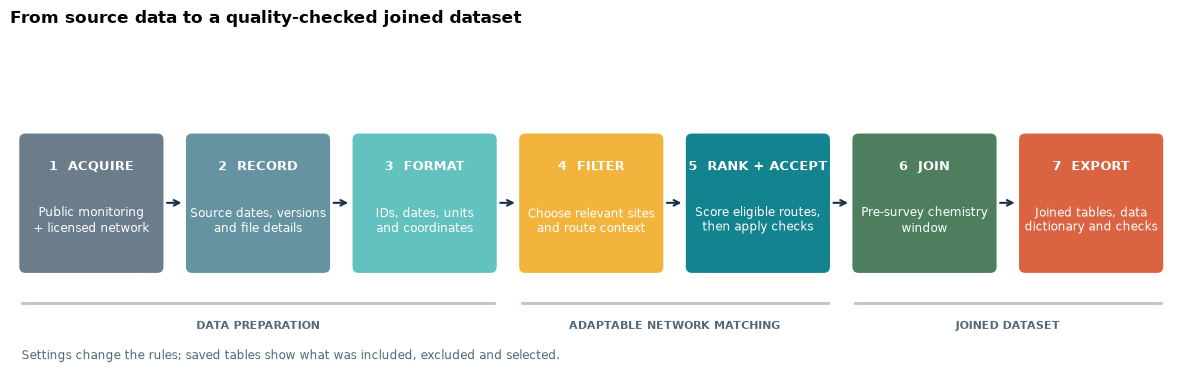

In [4]:
workflow_figure = plot_workflow_overview()
plt.show()


### Source data and refresh strategy

The sources update at different times and arrive as APIs, bulk downloads, tables and
spatial layers. The pipeline downloads them where possible and records the source,
retrieval date and file size. The table below comes directly from the source
catalogue used for this run. `required sources` is the number in each group needed for
the default England-wide joined dataset.

In [5]:
source_catalog = load_catalog()
source_groups = {
    "biology": "Biological monitoring",
    "integrated_monitoring": "Biological monitoring",
    "sensitivity": "Biological monitoring",
    "chemistry": "Chemistry and physical evidence",
    "hydrology": "Chemistry and physical evidence",
    "climate": "Chemistry and physical evidence",
    "habitat": "Chemistry and physical evidence",
    "water_resources": "Chemistry and physical evidence",
    "acute_pressure": "Pressures and regulation",
    "permitted_pressure": "Pressures and regulation",
    "physical_pressure": "Pressures and regulation",
    "pressures": "Pressures and regulation",
    "wastewater": "Pressures and regulation",
    "regulatory_status": "Pressures and regulation",
    "interventions": "Pressures and regulation",
    "network_topology": "Spatial framework",
    "spatial_reference": "Spatial framework",
    "land_cover": "Spatial framework",
    "natural_capital": "Spatial framework",
}
source_table = pd.DataFrame([
    {
        "source": name,
        "source group": source_groups[details.theme],
        "refresh": details.refresh,
        "required": details.required_for_release,
    }
    for name, details in source_catalog.items()
])
source_order = [
    "Biological monitoring", "Chemistry and physical evidence",
    "Pressures and regulation", "Spatial framework",
]
source_summary = (
    source_table.groupby("source group", as_index=False)
    .agg(
        sources=("source", "size"),
        refresh=("refresh", lambda values: ", ".join(sorted(set(values)))),
        required=("required", "sum"),
    )
    .assign(**{"source group": lambda frame: pd.Categorical(
        frame["source group"], categories=source_order, ordered=True
    )})
    .sort_values("source group")
    .rename(columns={"required": "required sources"})
)
display(Markdown(dataframe_markdown(source_summary, include_index=False)))

ranked_candidates = pd.read_parquet(
    RELEASE_DIR / "ranked_biology_chemistry_matches.parquet"
)
decisions = pd.read_parquet(
    RELEASE_DIR / "biology_chemistry_match_decisions.parquet"
)
network_qa = json.loads((RELEASE_DIR / "network_integration_qa.json").read_text())

| source group | sources | refresh | required sources |
| --- | --- | --- | --- |
| Biological monitoring | 3 | annually, monthly, quarterly | 3 |
| Chemistry and physical evidence | 6 | annually, biannually, daily | 3 |
| Pressures and regulation | 9 | annually, monthly, quarterly | 5 |
| Spatial framework | 4 | annually, quarterly, static | 2 |

### Harmonisation before matching

The catalogue lists where each source comes from and the run information records the files
actually used. Licensed river-network data are registered locally and are not copied into
the output.

Before matching, the code standardises sites, dates, coordinates, identifiers, units and
biological survey records. The specialist output keeps the original values and source
information. Missing measurements stay missing.

In [6]:
data_dictionary = pd.read_csv(
    RELEASE_DIR / "connected_river_data_dictionary.csv"
)
example_fields = [
    "bio_site_id", "sample_date", "easting", "northing",
    "taxon_richness", "wq_site_id", "network_distance_m",
    "match_decision", "chemistry_included_in_release",
]
harmonised_preview = data_dictionary.loc[
    data_dictionary["column"].isin(example_fields),
    ["column", "group", "data_type", "coverage_percent"],
].copy()
harmonised_preview["column"] = harmonised_preview["column"].replace({
    "bio_site_id": "biology site ID",
    "sample_date": "survey date",
    "taxon_richness": "taxon richness",
    "wq_site_id": "chemistry site ID",
    "network_distance_m": "river-network distance",
    "match_decision": "matching decision",
    "chemistry_included_in_release": "chemistry included",
})
harmonised_preview["group"] = harmonised_preview["group"].replace({
    "matching and interpretation": "matching",
})
site_detail_rows = harmonised_preview["group"].str.startswith(
    "identity", na=False
)
harmonised_preview.loc[site_detail_rows, "group"] = "site/source details"
harmonised_preview["coverage_percent"] = (
    harmonised_preview["coverage_percent"].round(1)
)
harmonised_preview = harmonised_preview.rename(columns={
    "column": "field", "data_type": "type",
    "coverage_percent": "coverage (%)",
})
display(Markdown(dataframe_markdown(harmonised_preview, include_index=False)))

| field | group | type | coverage (%) |
| --- | --- | --- | --- |
| survey date | site/source details | datetime64[us] | 100 |
| biology site ID | site/source details | string | 100 |
| easting | site/source details | float64 | 100 |
| northing | site/source details | float64 | 100 |
| taxon richness | biology | int64 | 100 |
| chemistry site ID | matching | string | 88.6 |
| river-network distance | matching | float64 | 88.6 |
| matching decision | matching | string | 100 |
| chemistry included | matching | boolean | 100 |

## Match sites through the river network

The table above comes from the generated data dictionary and describes the current
output. The final unit is one biological survey;
chemistry is added only after the source checks and matching steps below.

A nearby site is not necessarily on the same connected river. The workflow therefore
keeps the stages separate:

1. check which sites can be snapped to the network;
2. trace connected routes between plausible pairs;
3. describe distance, direction, tributaries and available monitoring evidence;
4. rank the eligible routes; and
5. apply the scientific acceptance checks.

The ranking step compares possible routes. A route must still pass the evidence checks
before it can be accepted.

### Candidate construction before selection

All connected alternatives are retained until a station is selected. For each route, the
table records distance, direction, snap quality, temporal support, tributaries, pressure
context, component scores and the final decision.

The first figure checks whether the supplied monitoring coordinates can be represented
on the national network. Later figures deal with whether those connections are suitable
for analysis.

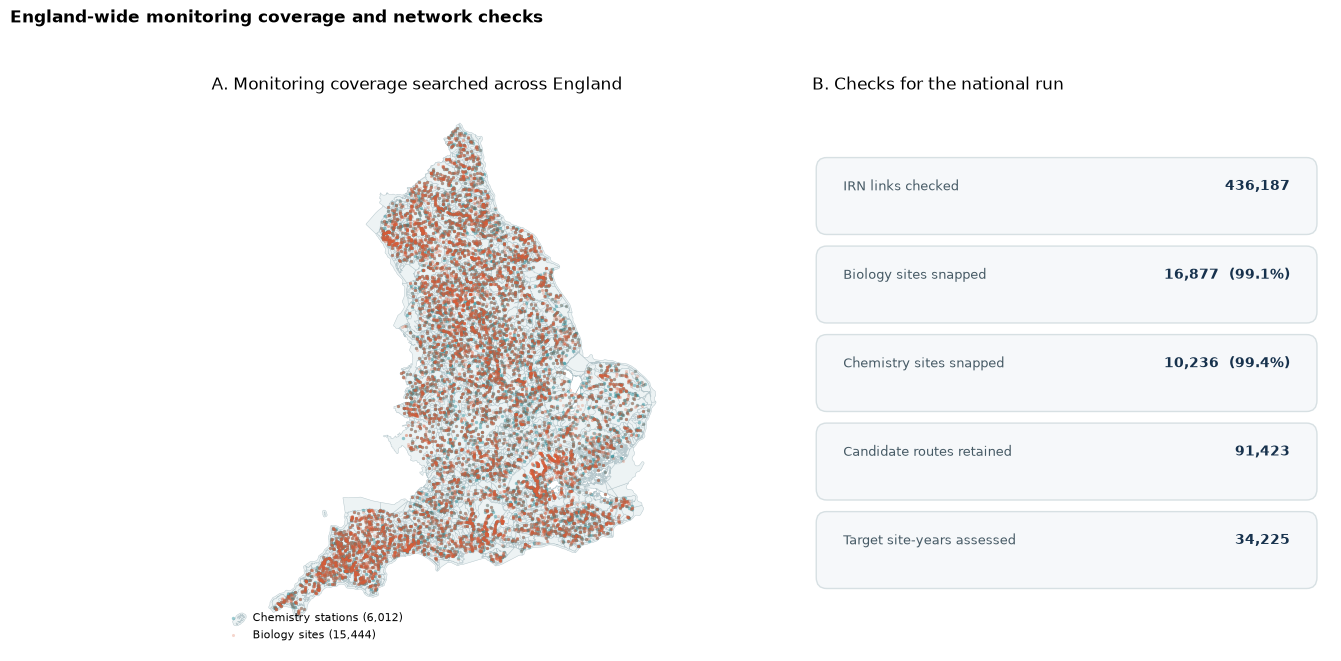

In [7]:
coverage_figure = plot_network_coverage(RELEASE_DIR)
plt.show()


### Ranking and scientific acceptance

The next cell prints a sample of the candidate table and follows one biological site
through the ranking step. The comparison keeps both the highest-scoring route and the
route selected after the evidence checks.

| biology site | year | chemistry station | river-network distance (km) | direction | decision |
| --- | --- | --- | --- | --- | --- |
| diatom:1000 | 2019 | NE-49700247 | 0 | WQ upstream | accept |
| diatom:1000 | 2019 | NE-49705106 | 7.1 | WQ upstream | reject |
| diatom:1000 | 2019 | NE-49700256 | 8.9 | WQ downstream | reject |
| diatom:1000 | 2019 | NE-49700101 | 1.5 | WQ upstream | reject |
| diatom:1000 | 2019 | NE-49700248 | 1.3 | WQ upstream | reject |

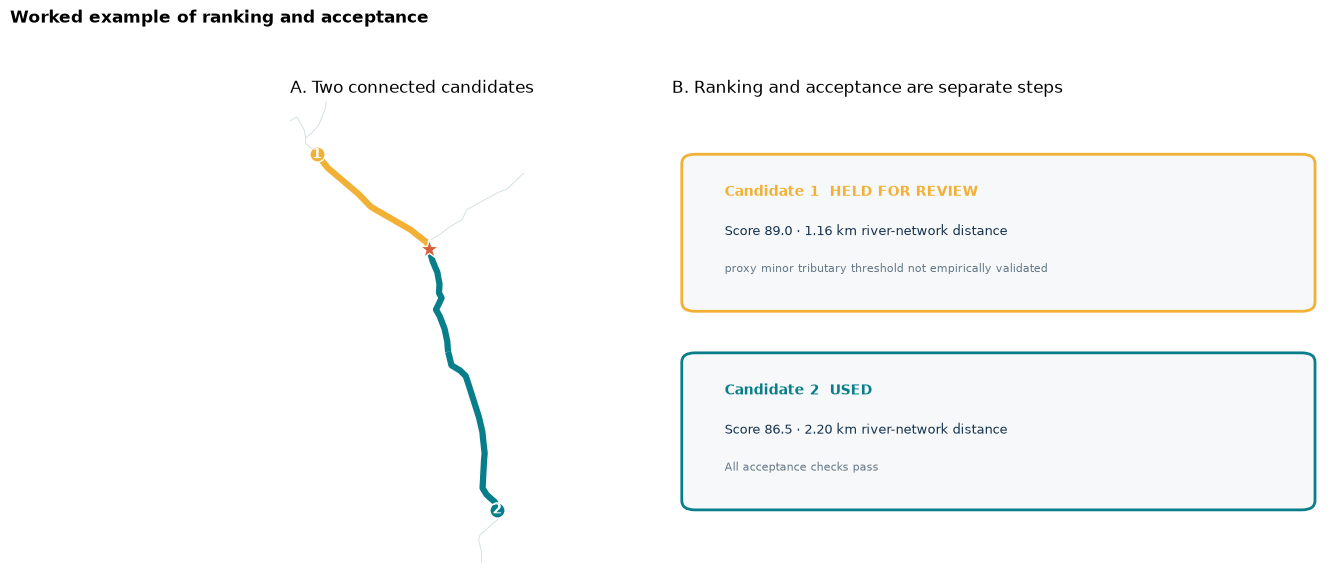

| station | rank | score | river-network distance (km) | direction | decision |
| --- | --- | --- | --- | --- | --- |
| MD-19235190 | 1 | 88.98 | 1.2 | WQ upstream | review |
| MD-19234410 | 2 | 86.51 | 2.2 | WQ downstream | accept |

In [8]:
candidate_preview = ranked_candidates[[
    "bio_site_id", "year", "wq_site_id", "network_distance_m",
    "network_direction", "candidate_gate_decision",
]].head(5).copy()
candidate_preview["network_distance_m"] = (
    candidate_preview["network_distance_m"] / 1_000
).round(1)
candidate_preview["network_direction"] = candidate_preview["network_direction"].replace({
    "wq_upstream_of_bio": "WQ upstream",
    "wq_downstream_of_bio": "WQ downstream",
})
candidate_preview = candidate_preview.rename(columns={
    "bio_site_id": "biology site", "wq_site_id": "chemistry station",
    "network_distance_m": "river-network distance (km)",
    "network_direction": "direction", "candidate_gate_decision": "decision",
})
display(Markdown(dataframe_markdown(candidate_preview, include_index=False)))

candidate_figure, worked_candidates = plot_candidate_decision_example(
    ranked_candidates, RELEASE_DIR
)
plt.show()

candidate_table = worked_candidates[[
    "wq_site_id", "match_rank", "match_score", "network_distance_m",
    "network_direction", "candidate_gate_decision",
]].copy()
candidate_table["network_distance_m"] = (
    candidate_table["network_distance_m"] / 1_000
).round(1)
candidate_table["network_direction"] = candidate_table["network_direction"].replace({
    "wq_upstream_of_bio": "WQ upstream",
    "wq_downstream_of_bio": "WQ downstream",
})
candidate_table = candidate_table.rename(columns={
    "wq_site_id": "station", "match_rank": "rank",
    "match_score": "score", "network_distance_m": "river-network distance (km)",
    "network_direction": "direction", "candidate_gate_decision": "decision",
})
display(Markdown(dataframe_markdown(candidate_table, include_index=False)))

## Adapt the matching recipe

A **matching recipe** is the set of choices used to move from all connected candidate
routes to one chemistry station for each biological survey. It has three parts:

1. candidate filters decide which routes are relevant to the question;
2. a 100-point score ranks the remaining routes; and
3. final checks decide whether the best available route can be included.

<div style="display:flex; align-items:stretch; gap:10px; margin:18px 0 20px 0;">
  <div style="flex:1; padding:12px; border:2px solid #2b7a78; border-radius:6px; background:#f1f8f7; text-align:center;">
    <strong style="font-size:1.15em;">FILTER</strong><br>
    <span>Which connected routes are eligible?</span>
  </div>
  <div style="align-self:center; font-size:1.7em;">→</div>
  <div style="flex:1; padding:12px; border:2px solid #315d83; border-radius:6px; background:#f2f6fa; text-align:center;">
    <strong style="font-size:1.15em;">RANK</strong><br>
    <span>Which eligible route has the strongest 100-point score?</span>
  </div>
  <div style="align-self:center; font-size:1.7em;">→</div>
  <div style="flex:1; padding:12px; border:2px solid #b36b2c; border-radius:6px; background:#fff7ef; text-align:center;">
    <strong style="font-size:1.15em;">ACCEPT</strong><br>
    <span>Does the best route pass the scientific checks?</span>
  </div>
</div>

The default ranking score is:

| Evidence used for ranking | Points |
|---|---:|
| River-network distance | 35 |
| Network snapping quality | 15 |
| Temporal support | 20 |
| Chemistry support | 20 |
| Transport plausibility | 10 |
| **Total** | **100** |

A higher score changes the ranking, but it does not bypass the acceptance checks. Custom
weights must also add to exactly 100 points.

The candidate table can therefore be reused for different questions without rewriting
the whole pipeline:

- require metals with `wq_has_metals:eq:true`;
- keep upstream chemistry with `network_direction:eq:wq_upstream_of_bio`;
- add route context such as `path_permitted_sewage_outlets:gt:0`;
- change `antecedent_window_months` from `6` to `12`;
- supply `CUSTOM_MATCH_RECIPE` to change the ranking weights; or
- use `custom_irn_schema` to map another directed river network.

Filters use `column:operator:value` and AND logic. They are applied before a winner is
selected, and the number of rows removed by each rule is saved.

In [9]:
eligible_candidates, filter_summary = apply_table_filters(
    ranked_candidates, CANDIDATE_ROUTE_FILTERS,
    label="user candidate-route eligibility",
)

if CUSTOM_MATCH_RECIPE:
    scored_candidates = apply_custom_matching_recipe(
        eligible_candidates, CUSTOM_MATCH_RECIPE
    )
    selected_matches = select_custom_matches(scored_candidates)
    recipe_table = recipe_terms_table(CUSTOM_MATCH_RECIPE)[["term", "points"]]
    recipe_table = recipe_table.rename(columns={"term": "component"})
else:
    scored_candidates = eligible_candidates.sort_values(
        ["bio_site_id", "year", "match_score", "network_distance_m", "wq_site_id"],
        ascending=[True, True, False, True, True],
    ).copy()
    scored_candidates["match_rank"] = (
        scored_candidates.groupby(["bio_site_id", "year"]).cumcount() + 1
    )
    selected_matches = select_candidates_by_scientific_gate(scored_candidates)
    recipe_table = pd.DataFrame({
        "component": [
            "river-network distance", "snapping quality", "temporal support",
            "chemistry support", "transport plausibility", "Total",
        ],
        "points": [35, 15, 20, 20, 10, 100],
    })

display(Markdown(
    f"**Current recipe:** {len(ranked_candidates):,} connected routes → "
    f"{len(eligible_candidates):,} eligible routes → "
    f"{len(selected_matches):,} selected site-years."
))
display(Markdown(dataframe_markdown(recipe_table, include_index=False)))


**Current recipe:** 91,423 connected routes → 91,423 eligible routes → 30,217 selected site-years.

| component | points |
| --- | --- |
| river-network distance | 35 |
| snapping quality | 15 |
| temporal support | 20 |
| chemistry support | 20 |
| transport plausibility | 10 |
| Total | 100 |

### What changes when the weights change?

The example below keeps the candidate filters and acceptance checks unchanged. It moves
10 points from river-network distance to chemistry support, so the total remains 100. This tests
the effect of the ranking choice on coverage and on the station selected for each survey.

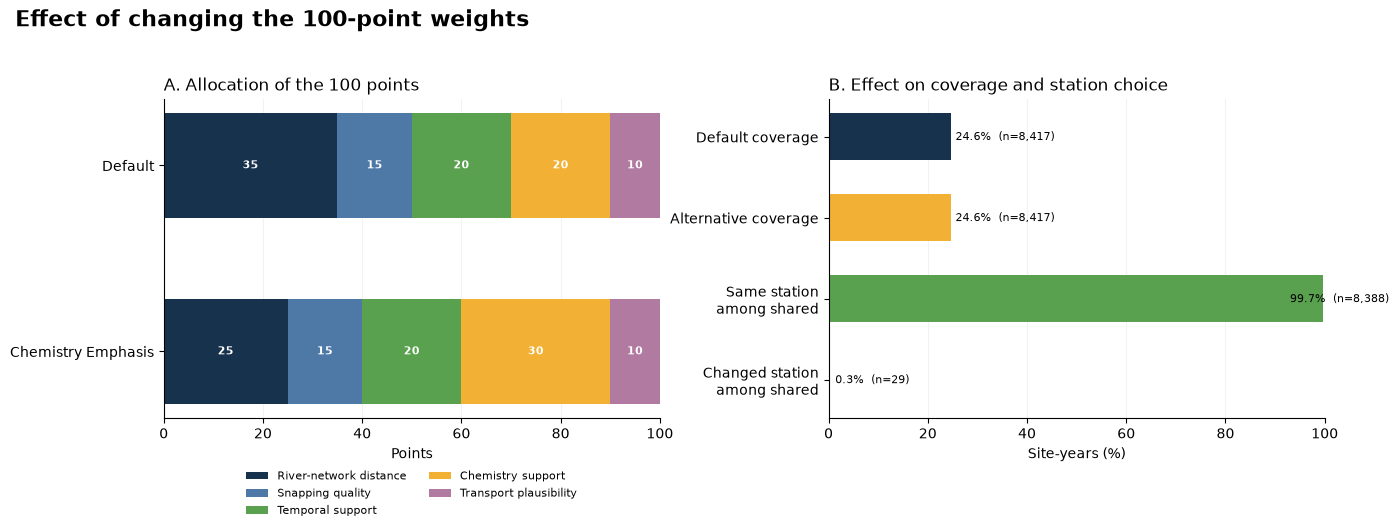

| recipe | points | usable site-years | coverage (%) | median river-network distance (km) | median chemistry support (%) | station changes vs default |
| --- | --- | --- | --- | --- | --- | --- |
| Default | 100 | 8,417 | 24.6 | 0 | 64.2 | 0 |
| chemistry_emphasis | 100 | 8,417 | 24.6 | 0 | 64.2 | 29 |

**Observed effect:** the new weights selected a different station for **29** of **8,417** shared site-years.

**Examples where the selected station changed**

| bio_site_id | year | default station | alternative station | default distance (km) | alternative distance (km) | default chemistry component | alternative chemistry component |
| --- | --- | --- | --- | --- | --- | --- | --- |
| diatom:100582 | 2018 | SW-50281306 | SW-50281314 | 0 | 2.2 | 13.7 | 20 |
| diatom:100582 | 2019 | SW-50281306 | SW-50281314 | 0 | 2.2 | 13.7 | 20 |
| diatom:202271 | 2021 | SO-RSN0089 | SO-E0007230 | 0 | 0.5 | 12.8 | 13.7 |
| diatom:202271 | 2022 | SO-RSN0089 | SO-E0007230 | 0 | 0.5 | 12.8 | 13.7 |

In [10]:
weight_figure, weight_summary, weight_changes = compare_recipe_weights(
    ranked_candidates, EXAMPLE_CHEMISTRY_EMPHASIS_RECIPE,
    total_site_years=int(network_qa["biology_site_year_rows"]),
    output_directory=WORKSPACE / "user_matching_outputs",
)
plt.show()

display_summary = weight_summary.drop(columns=[
    "shared with default", "same station among shared (%)",
])
for count_column in ("usable site-years", "station changes vs default"):
    display_summary[count_column] = display_summary[count_column].map(
        lambda value: f"{int(value):,}"
    )
display(Markdown(dataframe_markdown(display_summary.round(1), include_index=False)))

changed_count, shared_count = weight_summary.iloc[1][[
    "station changes vs default", "shared with default",
]]
display(Markdown(
    f"**Observed effect:** the new weights selected a different station for "
    f"**{int(changed_count):,}** of **{int(shared_count):,}** shared site-years."
))

if not weight_changes.empty:
    display(Markdown("**Examples where the selected station changed**"))
    display(Markdown(dataframe_markdown(
        weight_changes.head(4).round(1), include_index=False,
    )))


### Worked candidate pre-filter

This example keeps only chemistry stations upstream of the biological site. Direction
is a route property, so it can only be applied after candidate routes have been traced;
it is still a pre-filter for ranking and final selection. The example uses a separate
result and does not change the main national run.

In [11]:
example_filters = ["network_direction:eq:wq_upstream_of_bio"]
upstream_candidates, _ = apply_table_filters(
    ranked_candidates, example_filters, label="worked upstream candidate filter"
)
upstream_candidates = upstream_candidates.sort_values(
    ["bio_site_id", "year", "match_score", "network_distance_m", "wq_site_id"],
    ascending=[True, True, False, True, True],
).copy()
upstream_candidates["match_rank"] = (
    upstream_candidates.groupby(["bio_site_id", "year"]).cumcount() + 1
)
upstream_selected = select_candidates_by_scientific_gate(upstream_candidates)
upstream_counts = upstream_selected["candidate_gate_decision"].value_counts()

display(Markdown(
    f"**Worked result:** the filter retained **{len(upstream_candidates):,}** of "
    f"**{len(ranked_candidates):,}** connected routes and produced "
    f"**{int(upstream_counts.get('accept', 0)):,} accepted**, "
    f"**{int(upstream_counts.get('review', 0)):,} review** and "
    f"**{int(upstream_counts.get('reject', 0)):,} rejected** site-year selections."
))

upstream_example = upstream_selected[[
    "bio_site_id", "year", "wq_site_id", "network_distance_m",
    "candidate_gate_decision",
]].head(4).copy()
upstream_example["network_distance_m"] = (
    upstream_example["network_distance_m"] / 1_000
).round(1)
upstream_example = upstream_example.rename(columns={
    "bio_site_id": "biology site", "wq_site_id": "chemistry station",
    "network_distance_m": "river-network distance (km)",
    "candidate_gate_decision": "decision",
})
display(Markdown(dataframe_markdown(upstream_example, include_index=False)))


**Worked result:** the filter retained **49,623** of **91,423** connected routes and produced **6,556 accepted**, **6,299 review** and **10,008 rejected** site-year selections.

| biology site | year | chemistry station | river-network distance (km) | decision |
| --- | --- | --- | --- | --- |
| diatom:1000 | 2019 | NE-49700247 | 0 | accept |
| diatom:1000 | 2021 | NE-49700247 | 0 | reject |
| diatom:1000 | 2022 | NE-49700247 | 0 | review |
| diatom:10050 | 2023 | SW-82528154 | 1.1 | reject |

### What changes when candidate filters change?

These examples keep the 100-point weights fixed and change which routes are eligible.
The comparison shows how much coverage is retained and whether the selected chemistry
station changes.

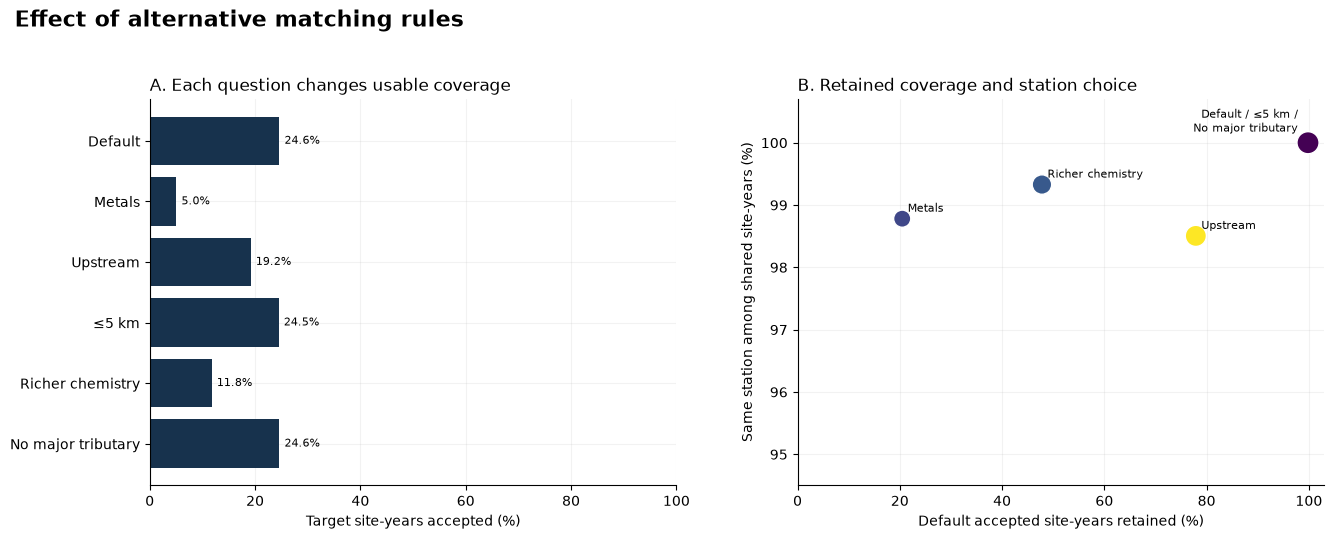

In [12]:
recipe_figure, recipe_comparison = compare_matching_recipes(
    ranked_candidates,
    total_site_years=int(network_qa["biology_site_year_rows"]),
    output_directory=WORKSPACE / "user_matching_outputs",
)
plt.show()


### Target-specific chemistry window

Chemistry is summarised separately for each biological survey date. Samples outside the
declared window are excluded, including any taken after the survey date.

The window is a user choice, not a fixed part of the method. Change
`MATCHING_OPTIONS["antecedent_window_months"]` in the settings cell (for example, from
`6` to `12`) and rebuild to use the previous year. The diagram below always reads the
active setting, while the run information records the value used to build the dataset.


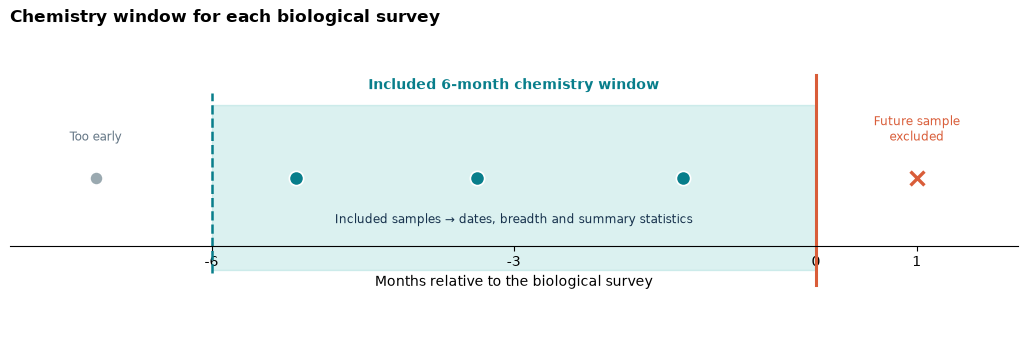

In [13]:
CHEMISTRY_WINDOW_MONTHS = int(MATCHING_OPTIONS["antecedent_window_months"])
# To test a different rule, edit the settings cell above, for example:
# MATCHING_OPTIONS["antecedent_window_months"] = 12

temporal_figure = plot_temporal_join(CHEMISTRY_WINDOW_MONTHS)
plt.show()


### Replacing the river network

The method is not tied to UKCEH field names. A different directed network can be used by
mapping its columns to the required fields below and setting `NETWORK_MODE` to
`custom_irn_schema`. The replacement needs line geometry in one projected CRS and a
consistent upstream-to-downstream node direction.

In [14]:
network_contract = network_contract_table(CUSTOM_NETWORK_COLUMNS)[[
    "pipeline field", "required", "configured source column", "check",
]].rename(columns={"configured source column": "source column"})
display(Markdown(dataframe_markdown(network_contract, include_index=False)))


| pipeline field | required | source column | check |
| --- | --- | --- | --- |
| edge_id | True | edge_id | unique and stable |
| from_node | True | from_node | upstream endpoint |
| to_node | True | to_node | downstream endpoint |
| length_m | True | length_m | finite and greater than zero |
| geometry_wkt | True | geometry_wkt | valid line in the declared CRS |
| strahler | False | strahler | positive where supplied |
| shreve | False | shreve | positive where supplied |
| river_name | False | river_name | descriptive only |
| area_id | False | area_id | regional grouping only |

### Review the matching outcomes

The decision table includes accepted matches, records held for review and cases where no
defensible match was found. The river-network-distance distribution is shown alongside those
outcomes.

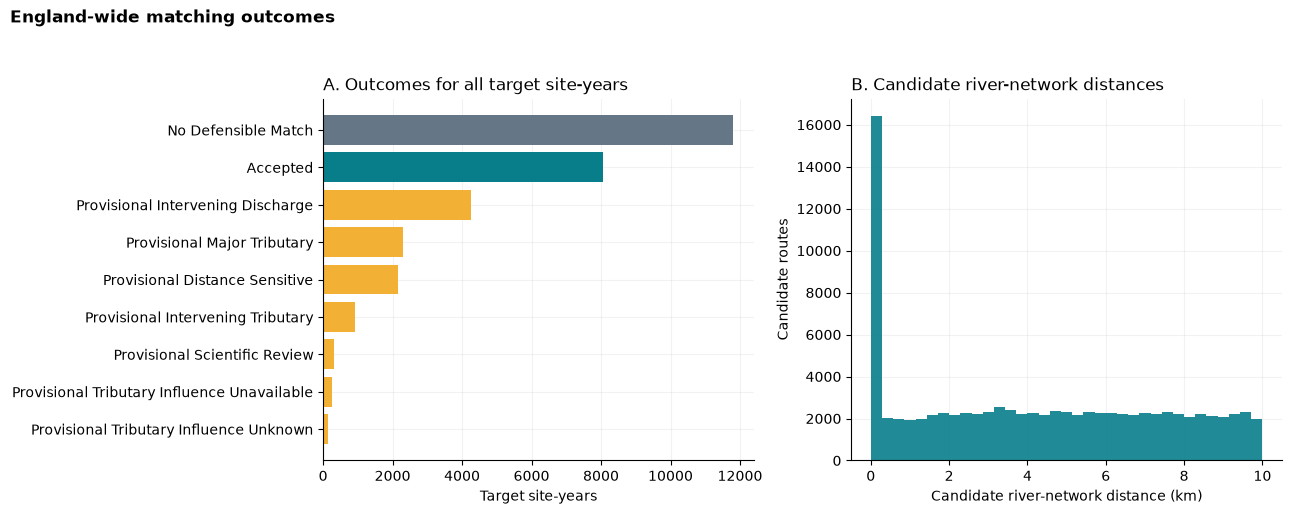

In [15]:
outcome_figure = plot_matching_outcomes(ranked_candidates, decisions)
plt.show()


## Write and verify the joined product

The configured workspace receives all generated data. The compact CSV is intended for
routine analysis; the specialist Parquet
keeps the full source schema, route evidence and matching diagnostics.

### Files created

The workflow creates three groups of outputs:

- the compact analysis table and full specialist table;
- all ranked routes, selected matches and filter/recipe settings; and
- the data dictionary, source details and output checks.

The next cell writes the current recipe and inspects the products that were actually
created.

In [16]:
output_directory, matching_manifest = write_matching_outputs(
    workspace=WORKSPACE,
    scored_candidates=scored_candidates,
    selected_matches=selected_matches,
    filter_audit=filter_summary,
    matching_options=MATCHING_OPTIONS,
    route_filters=CANDIDATE_ROUTE_FILTERS,
    custom_recipe=CUSTOM_MATCH_RECIPE,
    method_run=run_information,
)
completed = inspect_completed_dataset(RELEASE_DIR, output_directory)
completed_products = completed.paths
specialist_path = completed_products["Specialist joined Parquet"]

product_summary = completed.summary[[
    "product", "rows", "columns", "file size (MB)",
]].copy()
product_summary["rows"] = product_summary["rows"].map(lambda value: f"{int(value):,}")
product_summary["file size (MB)"] = product_summary["file size (MB)"].round(1)
display(Markdown(dataframe_markdown(product_summary, include_index=False)))

display(Markdown(
    f"**Output checks: {completed.qa['status'].upper()}.** "
    f"The joined dataset contains **{completed.parquet_file.metadata.num_rows:,} survey rows**. "
    "File details are saved alongside the output."
))
preview_columns = [
    "assemblage", "sample_year", "taxon_richness",
    "match_decision", "chemistry_included_in_release",
]
preview = completed.preview[preview_columns].rename(columns={
    "sample_year": "year", "taxon_richness": "richness",
    "match_decision": "matching decision",
    "chemistry_included_in_release": "chemistry included",
})
preview["assemblage"] = preview["assemblage"].replace({
    "freshwater_fish": "Freshwater fish",
    "transitional_coastal_fish": "Transitional/coastal fish",
})
display(Markdown(dataframe_markdown(
    preview, include_index=False
)))


| product | rows | columns | file size (MB) |
| --- | --- | --- | --- |
| Analysis-ready CSV | 53,256 | 370 | 18.6 |
| Specialist joined Parquet | 53,256 | 1236 | 25.5 |

**Output checks: PASSED.** The joined dataset contains **53,256 survey rows**. File details are saved alongside the output.

| assemblage | year | richness | matching decision | chemistry included |
| --- | --- | --- | --- | --- |
| diatom | 2018 | 102 | accepted | True |
| Freshwater fish | 2018 | 9 | accepted | True |
| macroinvertebrate | 2018 | 50 | accepted | True |
| macrophyte | 2018 | 18 | accepted | True |
| Transitional/coastal fish | 2018 | 5 | accepted | True |

### Check the joined data

Before the output is used, the checks compare record identities, data-dictionary coverage,
expected files and stored row counts. The saved matching tables also keep excluded candidates,
review reasons, route evidence and the settings used for the run.

In [17]:
output_files = {
    "all ranked routes": output_directory / "ranked_candidate_routes.parquet",
    "selected matches": output_directory / "selected_matches.parquet",
    "filter summary": output_directory / "filter_audit.json",
    "matching recipe": output_directory / "matching_recipe.json",
    "run information": output_directory / "run_manifest.json",
    "dataset information": output_directory / "completed_dataset_manifest.json",
    "data dictionary": RELEASE_DIR / "connected_river_data_dictionary.csv",
}
output_check = pd.DataFrame([
    {
        "record": label,
        "present": path.exists(),
        "size (MB)": round(path.stat().st_size / 1_000_000, 2) if path.exists() else None,
    }
    for label, path in output_files.items()
])
display(Markdown(dataframe_markdown(output_check, include_index=False)))

| record | present | size (MB) |
| --- | --- | --- |
| all ranked routes | True | 14.31 |
| selected matches | True | 5.05 |
| filter summary | True | 0 |
| matching recipe | True | 0 |
| run information | True | 0 |
| dataset information | True | 0 |
| data dictionary | True | 0.14 |

## What has been built?

This notebook turns separate monitoring records into a connected, traceable dataset. The
same sequence can be reused with different source data, another directed river network, a
different temporal window or a revised matching recipe.

Each run keeps the candidate routes, 100-point score, acceptance decisions, source
records, settings, source details, data dictionary and check results. A joined value can therefore
be traced back to the evidence and assumptions that produced it.

[The Connected River (Part 2) - Exploring](./The_Connected_River_Part_2_Exploring.ipynb)
starts with this completed dataset and shows what can be learned from it.